# Phase 3 · Rhetorical Role Prediction

<div align="center">

## MODEL2 · LoRA

**Parameter-efficient adaptation**

`CS781 Capstone` &nbsp; · &nbsp; `Corporate Law + IT` &nbsp; · &nbsp; `Sentence classification`

</div>

---

### Experiment at a glance

| Item | Configuration |
|:--|:--|
| **Phase 1 backbone** | `model2(3).ipynb` |
| **Architecture** | RoPE, RMSNorm, QK normalization, GQA and a SiLU feed-forward network |
| **Representation size** | 512-dimensional hidden states |
| **Adaptation method** | LoRA |
| **Checkpoint selection** | Development Macro-F1 |
| **Domains** | Corporate Law (CL) and Information Technology (IT) |

> **Objective**
>
> Adds trainable low-rank updates to selected attention projections while freezing their original weights. The classifier pools the target sentence’s final token, with previous-sentence context only. Training uses mild square-root inverse-frequency class weights computed from the training split.

### Before you run

1. Attach the **matching Phase 1 artifacts** as a Kaggle input dataset.
2. Set `ASSET_DIR` in the setup cell to that dataset's directory.
3. Confirm it contains `pytorch_model.bin` and `custom_bpe_scratch.json`.
4. Enable internet access and add a Kaggle Secret named `HF` containing a Hugging Face read token with access to `Exploration-Lab/CS-781-Capstone`.

> **Checkpoint safety:** Model 2 and Model 4 checkpoints/tokenizers are not interchangeable. This notebook uses the architecture and tokenizer implementation from its matching Phase 1 notebook; it does not use an external pretrained language model.

### Notebook workflow

`Setup` → `Tokenizer` → `Backbone` → `Data` → `Adaptation` → `Training & validation` → `Predictions`

---

**Important modeling correction in this version:** the original code appended the *next* sentence and then classified the last token of a causal decoder, so the pooled representation was from the next sentence rather than the labeled target. This version puts the target sentence last, includes only previous-sentence context, and prioritizes target tokens when truncating. It also uses capped square-root inverse-frequency class weights computed from training labels only.

**Run cells from top to bottom.** Training has not been executed in this environment, so no performance scores are claimed.


> **Hugging Face access required:** the notebook downloads the Phase-3 JSON files from `Exploration-Lab/CS-781-Capstone` using a token. In Kaggle, add a secret named `HF` with a read token and enable notebook access to secrets. Also attach the matching Phase-1 checkpoint and tokenizer files as a Kaggle Input.


F1-focused revision: target-sentence token mean pooling, cached tokenization, moderate training-only class weights, and a longer training budget.

In [5]:
import json, os, random, math
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('Device:', DEVICE)
ASSET_DIR = Path('/kaggle/input/datasets/baihuwang07/phase1')
OUTPUT_DIR = Path('/kaggle/working/phase3_rr')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

VOCAB_SIZE = 32000
N_LAYER = 15
N_HEAD = 8
N_KV_HEAD = 4
MODEL_CONTEXT_LENGTH = 2048
MAX_LENGTH = 256  # total context budget, including previous sentence
BATCH_SIZE = 4
EPOCHS = 8
WEIGHT_DECAY = 0.01
DROPOUT = 0.15
GRAD_CLIP = 1.0
DOMAIN = 'both'
USE_PREVIOUS_NEXT_SENTENCE_CONTEXT = True

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# Authenticate with a Kaggle Secret named HF. Never paste a real token into a notebook.
def get_hf_token():
    token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGING_FACE_HUB_TOKEN")
    if token:
        return token
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF")
    except Exception:
        token = None
    if not token:
        from getpass import getpass
        token = getpass("Hugging Face token (input hidden): ").strip()
    if not token:
        raise RuntimeError(
            "A Hugging Face token is required. In Kaggle, add a secret named 'HF' "
            "containing your token and enable access to secrets for this notebook."
        )
    return token

HF_TOKEN = get_hf_token()
os.environ["HF_TOKEN"] = HF_TOKEN
from huggingface_hub import hf_hub_download
print("Hugging Face authentication configured for", HF_DATASET_REPO)

def locate_asset(filename):
    root = Path(ASSET_DIR)
    if not root.exists():
        raise FileNotFoundError(f'Attach the matching Phase-1 asset dataset and set ASSET_DIR. Missing: {root}')
    hits = list(root.rglob(filename))
    if not hits:
        raise FileNotFoundError(f'{filename} not found below {root}')
    if len(hits) > 1:
        print('Multiple matches; using', hits[0])
    return hits[0]

def fetch_json(path):
    """Download a Phase-3 JSON file from the private Hugging Face dataset repo."""
    try:
        local_path = hf_hub_download(
            repo_id=HF_DATASET_REPO,
            filename=path,
            repo_type="dataset",
            token=HF_TOKEN,
        )
    except Exception as exc:
        raise RuntimeError(
            f"Could not download {path} from {HF_DATASET_REPO}. Check that your Hugging Face "
            "token is valid, has read access to the repository, and that the HF secret is "
            "named exactly 'HF' in Kaggle. Also verify that the file path exists in the repo. "
            f"Original error: {exc}"
        ) from exc
    with open(local_path, "r", encoding="utf-8") as f:
        return json.load(f)

def records_from_payload(payload, labeled=True):
    if isinstance(payload, dict):
        if 'text' in payload and 'id' in payload:
            docs = [payload]
        else:
            docs = []
            for did, v in payload.items():
                if isinstance(v, dict):
                    r = dict(v)
                    r.setdefault('id', str(did))
                    docs.append(r)
                else:
                    docs.append({'id': str(did), 'text': v})
    elif isinstance(payload, list):
        docs = payload
    else:
        raise ValueError('Unsupported payload type ' + str(type(payload)))
    out = []
    for d in docs:
        did = str(d.get('id', d.get('document_id', d.get('doc_id', ''))))
        ss = d.get('text', d.get('sentences', []))
        if isinstance(ss, str):
            ss = [ss]
        labs = d.get('labels', []) if labeled else None
        if labeled and (not isinstance(labs, list) or len(labs) != len(ss)):
            raise ValueError(f'{did}: label/sentence length mismatch')
        for i, s in enumerate(ss):
            out.append({'doc_id': did, 'sent_idx': i, 'sentence': str(s), 'label': labs[i] if labeled else None, 'sentences': ss})
    return out

def label_names_from_vocab(v):
    if isinstance(v, list):
        return list(map(str, v))
    if isinstance(v, dict):
        if all((isinstance(x, int) for x in v.values())):
            return [k for k, _ in sorted(v.items(), key=lambda kv: kv[1])]
        if all((str(k).isdigit() for k in v)):
            return [str(x) for k, x in sorted(v.items(), key=lambda kv: int(kv[0]))]
        return list(v.keys())
    raise ValueError('Unsupported label_vocab structure')

def context_text(r):
    # Kept for diagnostics; the dataset below separately marks target tokens.
    ss = r["sentences"]
    i = r["sent_idx"]
    parts = []
    if USE_PREVIOUS_NEXT_SENTENCE_CONTEXT and i > 0:
        parts.append("Previous sentence: " + ss[i - 1])
    parts.append("Target sentence: " + ss[i])
    return "\n".join(parts)


class RRDataset(Dataset):
    """Cache token IDs and mark only target-sentence tokens for pooling."""
    def __init__(self, records, tokenizer, label_to_id, labeled=True):
        self.items = []
        self.labeled = labeled
        for r in records:
            # Tokenize the target text separately. We pool hidden states only
            # over these tokens, not over the prompt or previous sentence.
            target_ids = tokenizer.encode(r["sentence"])
            if not target_ids:
                target_ids = [1]
            target_ids = target_ids[-MAX_LENGTH:]
            remaining = max(0, MAX_LENGTH - len(target_ids))
            prefix_text = "Target sentence: "
            if USE_PREVIOUS_NEXT_SENTENCE_CONTEXT and r["sent_idx"] > 0:
                prefix_text = "Previous sentence: " + r["sentences"][r["sent_idx"] - 1] + "\nTarget sentence: "
            prefix_ids = tokenizer.encode(prefix_text)[-remaining:] if remaining > 0 else []
            ids = prefix_ids + target_ids
            target_start = len(prefix_ids)
            target_mask = [False] * target_start + [True] * len(target_ids)
            item = {"input_ids": ids, "target_mask": target_mask, "record": r}
            if labeled:
                item["label"] = label_to_id[r["label"]]
            self.items.append(item)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        return self.items[index]


def collate_rr(batch):
    n = max(len(x["input_ids"]) for x in batch)
    ids = torch.zeros((len(batch), n), dtype=torch.long)
    mask = torch.zeros((len(batch), n), dtype=torch.bool)
    target_mask = torch.zeros((len(batch), n), dtype=torch.bool)
    for i, x in enumerate(batch):
        length = len(x["input_ids"])
        ids[i, :length] = torch.tensor(x["input_ids"], dtype=torch.long)
        mask[i, :length] = True
        target_mask[i, :length] = torch.tensor(x["target_mask"], dtype=torch.bool)
    labels = torch.tensor([x["label"] for x in batch], dtype=torch.long) if "label" in batch[0] else None
    return ids, mask, target_mask, labels, [x["record"] for x in batch]


class SentenceClassifier(nn.Module):
    def __init__(self, backbone, hidden_size, num_labels):
        super().__init__()
        self.backbone = backbone
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(hidden_size, num_labels)

    def forward(self, ids, mask, target_mask):
        h = self.backbone.forward_hidden(ids, attention_mask=mask)
        # Mean-pool contextualized hidden states of the labeled sentence only.
        weights = target_mask.unsqueeze(-1).to(h.dtype)
        pooled = (h * weights).sum(dim=1) / weights.sum(dim=1).clamp_min(1.0)
        return self.classifier(self.dropout(pooled))


def evaluate(model, loader, nlabels):
    model.eval()
    ys, ps = [], []
    tot, n = 0.0, 0
    with torch.no_grad():
        for ids, mask, target_mask, y, _ in loader:
            ids = ids.to(DEVICE)
            mask = mask.to(DEVICE)
            target_mask = target_mask.to(DEVICE)
            y = y.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                z = model(ids, mask, target_mask)
                loss = F.cross_entropy(z.float(), y, reduction="sum")
            tot += loss.item()
            n += y.numel()
            ys.extend(y.cpu().tolist())
            ps.extend(z.argmax(-1).cpu().tolist())
    labels = list(range(nlabels))
    return ({
        "loss": tot / max(n, 1),
        "macro_f1": f1_score(ys, ps, average="macro", labels=labels, zero_division=0),
        "macro_precision": precision_score(ys, ps, average="macro", labels=labels, zero_division=0),
        "macro_recall": recall_score(ys, ps, average="macro", labels=labels, zero_division=0),
    }, ys, ps)

def train_model(model, train_loader, dev_loader, label_names, optimizer, extra_loss=None):
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type == 'cuda')
    best = -1
    hist = []
    ckpt_path = OUTPUT_DIR / 'best_rr_checkpoint.pt'
    for ep in range(1, EPOCHS + 1):
        model.train()
        running = 0.0
        seen = 0
        for ids, mask, target_mask, y, _ in train_loader:
            ids = ids.to(DEVICE)
            mask = mask.to(DEVICE)
            target_mask = target_mask.to(DEVICE)
            y = y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == 'cuda'):
                logits = model(ids, mask, target_mask)
                # Compute weighted CE in FP32 for numerical stability.
                loss = F.cross_entropy(logits.float(), y, weight=TRAIN_CLASS_WEIGHTS)
                if extra_loss:
                    loss = extra_loss(loss, logits, ids, mask, y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            running += float(loss.detach()) * y.numel()
            seen += y.numel()
        met, _, _ = evaluate(model, dev_loader, len(label_names))
        hist.append({'epoch': ep, 'train_loss': running / max(seen, 1), **met})
        print(f"epoch={ep} train_loss={running / max(seen, 1):.4f} dev_macro_f1={met['macro_f1']:.4f}")
        if met['macro_f1'] > best:
            best = met['macro_f1']
            torch.save({'model_state_dict': model.state_dict(), 'epoch': ep, 'metrics': met, 'label_names': label_names}, ckpt_path)
    ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck['model_state_dict'])
    json.dump(hist, open(OUTPUT_DIR / 'training_history.json', 'w'), indent=2)
    plt.figure(figsize=(7, 4))
    plt.plot([x['epoch'] for x in hist], [x['train_loss'] for x in hist], marker='o', label='train')
    plt.plot([x['epoch'] for x in hist], [x['loss'] for x in hist], marker='o', label='dev')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'loss_curve.png', dpi=150)
    plt.show()
    return (model, hist, ckpt_path)

def save_predictions(model, records, label_names, label_to_id, suffix):
    loader = DataLoader(RRDataset(records, tokenizer, label_to_id, False), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_rr)
    pred = {}
    model.eval()
    with torch.no_grad():
        for ids, mask, target_mask, _, rs in loader:
            ys = model(ids.to(DEVICE), mask.to(DEVICE), target_mask.to(DEVICE)).argmax(-1).cpu().tolist()
            for r, y in zip(rs, ys):
                pred.setdefault(r['doc_id'], {})[r['sent_idx']] = label_names[y]
    ordered = {}
    for r in records:
        if r['doc_id'] not in ordered:
            ordered[r['doc_id']] = [None] * len(r['sentences'])
        ordered[r['doc_id']][r['sent_idx']] = pred[r['doc_id']][r['sent_idx']]
    assert all((x is not None for vv in ordered.values() for x in vv))
    p = OUTPUT_DIR / f'{suffix}_prediction.json'
    json.dump(ordered, open(p, 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
    return p

# Notes preserved from the original cell:
# CHANGE to the matching Phase-1 dataset directory


Device: cuda
Hugging Face authentication configured for Exploration-Lab/CS-781-Capstone


## 1. Phase-1 custom byte-level BPE tokenizer

Exact tokenizer class extracted from the matching Phase-1 notebook.

In [6]:
import re
from collections import Counter, defaultdict

class CustomByteLevelBPE:

    def __init__(self, vocab_size=32000):
        self.vocab_size = vocab_size
        self.merges = {}
        self.vocab = {i: bytes([i]) for i in range(256)}
        self.inverse_vocab = {bytes([i]): i for i in range(256)}
        self.next_id = 256
        self.pad_id = 0

    def train(self, texts, target_vocab_size):
        print('Aggregating byte sequence frequencies...')
        word_freqs = Counter()
        for text in texts:
            chunks = re.findall('\\S+|\\s+', text)
            for chunk in chunks:
                word_freqs[chunk.encode('utf-8')] += 1
        word_freqs = {w: f for w, f in word_freqs.items() if f > 1}
        print(f'Unique byte sequences to process: {len(word_freqs):,}')
        splits = {word: list(word) for word in word_freqs}
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)
        for word, freq in word_freqs.items():
            split = splits[word]
            for j in range(len(split) - 1):
                pair = (split[j], split[j + 1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)
        num_merges = target_vocab_size - 256
        print(f'Starting {num_merges} merges...')
        for i in range(num_merges):
            if not pair_counts:
                break
            best_pair = max(pair_counts, key=pair_counts.get)
            new_id = self.next_id
            self.merges[best_pair] = new_id
            self.vocab[new_id] = self.vocab[best_pair[0]] + self.vocab[best_pair[1]]
            self.inverse_vocab[self.vocab[new_id]] = new_id
            words_to_update = list(pair_to_words.get(best_pair, []))
            del pair_counts[best_pair]
            if best_pair in pair_to_words:
                del pair_to_words[best_pair]
            for word in words_to_update:
                split = splits[word]
                freq = word_freqs[word]
                for j in range(len(split) - 1):
                    pair = (split[j], split[j + 1])
                    if pair != best_pair:
                        pair_counts[pair] -= freq
                        if pair_counts[pair] <= 0:
                            del pair_counts[pair]
                        if word in pair_to_words.get(pair, set()):
                            pair_to_words[pair].remove(word)
                new_split = []
                j = 0
                while j < len(split):
                    if j < len(split) - 1 and (split[j], split[j + 1]) == best_pair:
                        new_split.append(new_id)
                        j += 2
                    else:
                        new_split.append(split[j])
                        j += 1
                splits[word] = new_split
                for j in range(len(new_split) - 1):
                    pair = (new_split[j], new_split[j + 1])
                    pair_counts[pair] += freq
                    pair_to_words[pair].add(word)
            self.next_id += 1
            if (i + 1) % 1000 == 0:
                print(f'Merge {i + 1}/{num_merges} completed.')
        print('BPE Training complete!')

    def _get_stats(self, ids):
        counts = Counter()
        for i in range(len(ids) - 1):
            counts[ids[i], ids[i + 1]] += 1
        return counts

    def _merge_vocab(self, ids, pair, idx):
        newids = []
        i = 0
        while i < len(ids):
            if i < len(ids) - 1 and ids[i] == pair[0] and (ids[i + 1] == pair[1]):
                newids.append(idx)
                i += 2
            else:
                newids.append(ids[i])
                i += 1
        return newids

    def encode(self, text):
        chunks = re.findall('\\S+|\\s+', text)
        final_ids = []
        for chunk in chunks:
            ids = list(chunk.encode('utf-8'))
            while len(ids) >= 2:
                stats = self._get_stats(ids)
                pair = min(stats.keys(), key=lambda p: self.merges.get(p, float('inf')))
                if pair not in self.merges:
                    break
                ids = self._merge_vocab(ids, pair, self.merges[pair])
            final_ids.extend(ids)
        return final_ids

    def decode(self, ids):
        b_text = b''.join((self.vocab[idx] for idx in ids if idx != self.pad_id))
        return b_text.decode('utf-8', errors='replace')

    def get_vocab_size(self):
        return len(self.vocab)

    def save(self, path):
        serializable_merges = {f'{p[0]},{p[1]}': v for p, v in self.merges.items()}
        serializable_vocab = {k: list(v) for k, v in self.vocab.items()}
        data = {'vocab_size': self.vocab_size, 'next_id': self.next_id, 'merges': serializable_merges, 'vocab': serializable_vocab}
        with open(path, 'w', encoding='utf-8') as f:
            json.dump(data, f, ensure_ascii=False)

    def load(self, path):
        with open(path, 'r', encoding='utf-8') as f:
            data = json.load(f)
        self.vocab_size = data['vocab_size']
        self.next_id = data['next_id']
        self.merges = {tuple(map(int, k.split(','))): v for k, v in data['merges'].items()}
        self.vocab = {int(k): bytes(v) for k, v in data['vocab'].items()}
        self.inverse_vocab = {v: k for k, v in self.vocab.items()}

# Notes preserved from the original cell:
# Base vocabulary of all 256 individual bytes
# Reserved Special Tokens
# 1. Chunk texts to prevent massive contiguous memory blocks
# Split into words and whitespace blocks to keep sequence lengths small
# 2. Drop singletons to massively save RAM
# Initialize splits: word -> list of byte integers
# 3. Build fast inverted index
# Record the merge
# 4. FAST INCREMENTAL UPDATE: Only process words containing the best_pair
# Remove old pairs associated with this word from global tracking
# Execute the merge on this word's internal list
# Add newly formed pairs back to global tracking
# Chunk text during encoding to prevent \(O(N^2)\) slowdowns on long documents


## 2. Phase-1 model architecture

Exact custom model classes from the supplied notebook; only original model instantiation is omitted.

In [7]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):

    def __init__(self, dim, eps=1e-06):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def precompute_freqs_cis(dim, end, theta=10000.0):
    freqs = 1.0 / theta ** (torch.arange(0, dim, 2)[:dim // 2].float() / dim)
    t = torch.arange(end, device=freqs.device)
    freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
    return torch.view_as_real(freqs_cis)

def apply_rotary_emb(xq, xk, freqs_cis):
    xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = freqs_cis.view(1, xq_.shape[1], 1, xq_.shape[-1])
    return (torch.view_as_real(xq_ * freqs_cis).flatten(3).type_as(xq), torch.view_as_real(xk_ * freqs_cis).flatten(3).type_as(xk))

class ManualTransformerAttention(nn.Module):

    def __init__(self, head_dim):
        super().__init__()
        self.scale = 1.0 / math.sqrt(head_dim)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, is_causal: bool=True, attention_mask=None):
        B, H, L_q, D = q.shape
        _, _, L_k, _ = k.shape
        k_transposed = k.transpose(-2, -1).contiguous()
        scores = torch.matmul(q, k_transposed) * self.scale
        if is_causal and L_q > 1:
            mask = torch.tril(torch.ones(L_q, L_k, device=q.device)).view(1, 1, L_q, L_k)
            scores = scores.masked_fill(mask == 0, float('-inf'))
        if attention_mask is not None:
            pad_mask = attention_mask.view(attention_mask.size(0), 1, 1, attention_mask.size(1))
            scores = scores.masked_fill(pad_mask == 0, float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        return torch.matmul(weights, v.contiguous())

class GroupedQueryAttention(nn.Module):

    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.n_heads, self.n_kv_heads, self.head_dim = (n_heads, n_kv_heads, dim // n_heads)
        self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(dim, dim, bias=False)
        self.q_norm = RMSNorm(n_heads * self.head_dim)
        self.k_norm = RMSNorm(n_kv_heads * self.head_dim)
        self.manual_attention = ManualTransformerAttention(self.head_dim)

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        B, L, _ = x.shape
        q = self.q_norm(self.wq(x)).view(B, L, self.n_heads, self.head_dim)
        k = self.k_norm(self.wk(x)).view(B, L, self.n_kv_heads, self.head_dim)
        v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)
        q, k = apply_rotary_emb(q, k, freqs_cis)
        if kv_cache is not None:
            k_cache, v_cache = kv_cache
            k = torch.cat([k_cache, k], dim=1)
            v = torch.cat([v_cache, v], dim=1)
        new_kv_cache = (k, v)
        k_rep = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        v_rep = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        out = self.manual_attention(q=q.transpose(1, 2), k=k_rep.transpose(1, 2), v=v_rep.transpose(1, 2), is_causal=L > 1, attention_mask=attention_mask)
        out = out.transpose(1, 2).contiguous().view(B, L, -1)
        return (self.wo(out), new_kv_cache)

class CustomTransformerBlock(nn.Module):

    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.norm1 = RMSNorm(dim)
        self.norm2 = RMSNorm(dim)
        self.attn = GroupedQueryAttention(dim, n_heads, n_kv_heads)
        self.ffn = nn.Sequential(nn.Linear(dim, dim * 4, bias=False), nn.SiLU(), nn.Linear(dim * 4, dim, bias=False))

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        attn_out, new_kv_cache = self.attn(self.norm1(x), freqs_cis, kv_cache, attention_mask=attention_mask)
        h = x + attn_out
        out = h + self.ffn(self.norm2(h))
        return (out, new_kv_cache)

class CustomLegalModel(nn.Module):

    def __init__(self, vocab_size, dim, n_layers, n_heads, n_kv_heads, max_seq_len):
        super().__init__()
        self.tok_embeddings = nn.Embedding(vocab_size, dim)
        self.layers = nn.ModuleList([CustomTransformerBlock(dim, n_heads, n_kv_heads) for _ in range(n_layers)])
        self.norm = RMSNorm(dim)
        self.output = nn.Linear(dim, vocab_size, bias=False)
        self.output.weight = self.tok_embeddings.weight
        self.register_buffer('freqs_cis', precompute_freqs_cis(dim // n_heads, max_seq_len))

    def forward(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
        B, L = tokens.shape
        freqs_cis = self.freqs_cis[start_pos:start_pos + L].to(tokens.device)
        freqs_cis = torch.view_as_complex(freqs_cis)
        h = self.tok_embeddings(tokens)
        new_caches = []
        for i, layer in enumerate(self.layers):
            cache_i = kv_caches[i] if kv_caches is not None else None
            h, new_cache = layer(h, freqs_cis, kv_cache=cache_i, attention_mask=attention_mask)
            new_caches.append(new_cache)
        return (self.output(self.norm(h)), new_caches)

# Notes preserved from the original cell:
# ==========================================
# 4. Custom Architecture (RoPE, RMSNorm, GQA, QK-Norm, Sequential)
# ==========================================
# Apply padding mask for batched inference
# QK-Norm layers for stabilization
# Apply QK-Norm directly after linear projections
# class SwiGLU_FFN(nn.Module):
#     def __init__(self, dim, hidden_dim=None):
#         super().__init__()
#         if hidden_dim is None:
#             hidden_dim = int(8 * dim / 3)
#             hidden_dim = 256 * ((hidden_dim + 255) // 256)
#         self.w1 = nn.Linear(dim, hidden_dim, bias=False)
#         self.w2 = nn.Linear(hidden_dim, dim, bias=False)
#         self.w3 = nn.Linear(dim, hidden_dim, bias=False)
#     def forward(self, x):
#         return self.w2(F.silu(self.w1(x)) * self.w3(x))
# Restored separate norm layers for sequential architecture
# Standard Sequential FFN with SiLU (Swish) instead of GELU
# Sequential Residual Architecture
# ---------------------------------------------
# Re-instantiate the model 
# ---------------------------------------------


In [8]:
N_EMBD = 512
MODEL_CONTEXT_LENGTH = 2048
backbone = CustomLegalModel(VOCAB_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD, MODEL_CONTEXT_LENGTH)

def _forward_hidden(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
    B, L = tokens.shape
    freqs_cis = torch.view_as_complex(self.freqs_cis[start_pos:start_pos + L].to(tokens.device))
    h = self.tok_embeddings(tokens)
    for layer in self.layers:
        h, _ = layer(h, freqs_cis, kv_cache=None, attention_mask=attention_mask)
    return self.norm(h)

backbone.forward_hidden = _forward_hidden.__get__(backbone, CustomLegalModel)
checkpoint_path = locate_asset('pytorch_model.bin')
tokenizer_path = locate_asset('custom_bpe_scratch.json')
state = torch.load(checkpoint_path, map_location='cpu', weights_only=True)

if isinstance(state, dict) and 'model_state_dict' in state:
    state = state['model_state_dict']
backbone.load_state_dict(state, strict=True)
backbone.to(DEVICE)
tokenizer = CustomByteLevelBPE(vocab_size=VOCAB_SIZE)
tokenizer.load(str(tokenizer_path))
print('Loaded matching Model2 checkpoint:', checkpoint_path, 'tokenizer:', tokenizer_path)


Loaded matching Model2 checkpoint: /kaggle/input/datasets/baihuwang07/phase1/pytorch_model.bin tokenizer: /kaggle/input/datasets/baihuwang07/phase1/custom_bpe_scratch.json


## 3. Phase-3 data and sentence examples

Development Macro-F1 is used for model selection. Both domains are enabled by default.

In [9]:
data = {k: fetch_json(v) for k, v in {'CL_train': 'Phase_3_RR/Train/CL_train.json', 'IT_train': 'Phase_3_RR/Train/IT_train.json', 'CL_dev': 'Phase_3_RR/Train/CL_dev.json', 'IT_dev': 'Phase_3_RR/Train/IT_dev.json', 'label_vocab': 'Phase_3_RR/Train/label_vocab.json', 'CL_test': 'Phase_3_RR/Test/CL_test.json', 'IT_test': 'Phase_3_RR/Test/IT_test.json'}.items()}

label_names = label_names_from_vocab(data['label_vocab'])
label_to_id = {v: i for i, v in enumerate(label_names)}
assert len(label_names) == len(set(label_names)), 'Duplicate label names in label_vocab.'
assert all(label_names[idx] == name for name, idx in label_to_id.items()), 'Inconsistent label mapping.'

keys = ['CL', 'IT'] if DOMAIN == 'both' else [DOMAIN]
train_records = sum((records_from_payload(data[k + '_train'], True) for k in keys), [])
dev_records = sum((records_from_payload(data[k + '_dev'], True) for k in keys), [])
test_records = sum((records_from_payload(data[k + '_test'], False) for k in keys), [])

train_loader = DataLoader(RRDataset(train_records, tokenizer, label_to_id, True), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_rr)
dev_loader = DataLoader(RRDataset(dev_records, tokenizer, label_to_id, True), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_rr)
# Mild inverse-frequency weighting for macro-F1; computed from training labels only.
# Square-root weighting avoids the extreme gradients caused by full inverse frequency.
from collections import Counter

_train_counts = Counter(label_to_id[r["label"]] for r in train_records)
_train_count_tensor = torch.tensor(
    [_train_counts.get(i, 0) for i in range(len(label_names))],
    dtype=torch.float32,
)
TRAIN_CLASS_WEIGHTS = torch.ones_like(_train_count_tensor)
_present = _train_count_tensor > 0
TRAIN_CLASS_WEIGHTS[_present] = (
    _train_count_tensor[_present].sum() / _train_count_tensor[_present]
).sqrt()
TRAIN_CLASS_WEIGHTS /= TRAIN_CLASS_WEIGHTS[_present].mean()
TRAIN_CLASS_WEIGHTS.clamp_(min=0.5, max=3.0)
TRAIN_CLASS_WEIGHTS = TRAIN_CLASS_WEIGHTS.to(DEVICE)
print("Training class weights:", {
    name: round(float(TRAIN_CLASS_WEIGHTS[i].item()), 3)
    for i, name in enumerate(label_names)
})

print('Labels:', label_names)
print('Train/dev/test sentences:', len(train_records), len(dev_records), len(test_records))


CL_train.json:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

IT_train.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

CL_dev.json:   0%|          | 0.00/336k [00:00<?, ?B/s]

IT_dev.json:   0%|          | 0.00/165k [00:00<?, ?B/s]

label_vocab.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

CL_test.json:   0%|          | 0.00/281k [00:00<?, ?B/s]

IT_test.json:   0%|          | 0.00/194k [00:00<?, ?B/s]

Training class weights: {'Fact': 0.5, 'Issue': 1.186, 'ArgumentPetitioner': 0.5, 'ArgumentRespondent': 0.5, 'Statute': 0.5, 'Dissent': 0.728, 'PrecedentReliedUpon': 0.5, 'PrecedentNotReliedUpon': 0.514, 'PrecedentOverruled': 3.0, 'RulingByLowerCourt': 0.5, 'RatioOfTheDecision': 0.5, 'RulingByPresentCourt': 0.7, 'None': 0.712}
Labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']
Train/dev/test sentences: 16845 2142 2197


## 04 · LoRA

The method-specific implementation below is applied to this notebook's matching Phase 1 backbone.

In [10]:
METHOD = 'LoRA'
LR_BACKBONE = 0.0001
LR_HEAD = 0.0003
RANK = 8
ALPHA = 16.0
ADAPTER_DROPOUT = 0.05

class LoRALinear(nn.Module):

    def __init__(self, base):
        super().__init__()
        self.base = base
        for p in base.parameters():
            p.requires_grad = False
        self.scale = ALPHA / RANK
        self.drop = nn.Dropout(ADAPTER_DROPOUT)
        self.A = nn.Parameter(torch.empty(RANK, base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, RANK))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))

    def forward(self, x):
        return self.base(x) + F.linear(F.linear(self.drop(x), self.A), self.B) * self.scale

def adapt(b):
    for p in b.parameters():
        p.requires_grad = False
    for layer in b.layers:
        for name in ('wq', 'wk', 'wv', 'wo'):
            setattr(layer.attn, name, LoRALinear(getattr(layer.attn, name)))
    return b


In [11]:
backbone = adapt(backbone)
model = SentenceClassifier(backbone, N_EMBD, len(label_names)).to(DEVICE)
print('Trainable params:', sum((p.numel() for p in model.parameters() if p.requires_grad)), '/', sum((p.numel() for p in model.parameters())))
optimizer = torch.optim.AdamW([{'params': [p for p in model.backbone.parameters() if p.requires_grad], 'lr': LR_BACKBONE}, {'params': model.classifier.parameters(), 'lr': LR_HEAD}], weight_decay=WEIGHT_DECAY)


Trainable params: 436749 / 60101901


## 5. Train and evaluate on development data

epoch=1 train_loss=1.9279 dev_macro_f1=0.1365
epoch=2 train_loss=1.6871 dev_macro_f1=0.1882
epoch=3 train_loss=1.5490 dev_macro_f1=0.1987
epoch=4 train_loss=1.4389 dev_macro_f1=0.2299
epoch=5 train_loss=1.3459 dev_macro_f1=0.2463
epoch=6 train_loss=1.2610 dev_macro_f1=0.2347
epoch=7 train_loss=1.1955 dev_macro_f1=0.2563
epoch=8 train_loss=1.1263 dev_macro_f1=0.2705


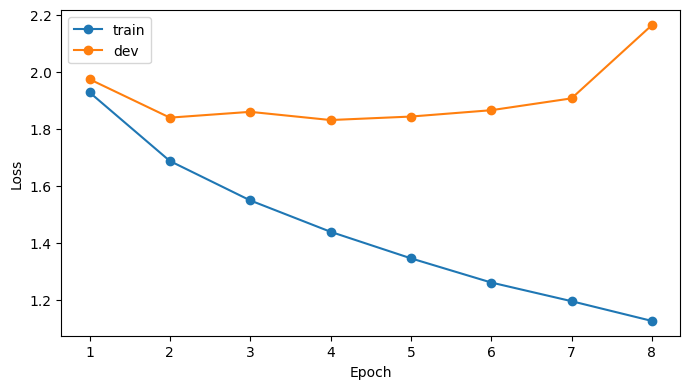

In [12]:
model, history, best_path = train_model(model, train_loader, dev_loader, label_names, optimizer)


Development metrics: {
  "loss": 2.1634658695238596,
  "macro_f1": 0.2705354930502366,
  "macro_precision": 0.3068411243417636,
  "macro_recall": 0.28620516005899427
}
                        precision    recall  f1-score   support

                  Fact       0.49      0.64      0.56       444
                 Issue       0.27      0.40      0.32        15
    ArgumentPetitioner       0.52      0.19      0.28       400
    ArgumentRespondent       0.50      0.12      0.20       272
               Statute       0.63      0.78      0.70       120
               Dissent       0.00      0.00      0.00         0
   PrecedentReliedUpon       0.28      0.40      0.33       254
PrecedentNotReliedUpon       0.20      0.06      0.09        50
    PrecedentOverruled       0.00      0.00      0.00         0
    RulingByLowerCourt       0.16      0.04      0.06       102
    RatioOfTheDecision       0.31      0.54      0.39       403
  RulingByPresentCourt       0.32      0.29      0.30        49

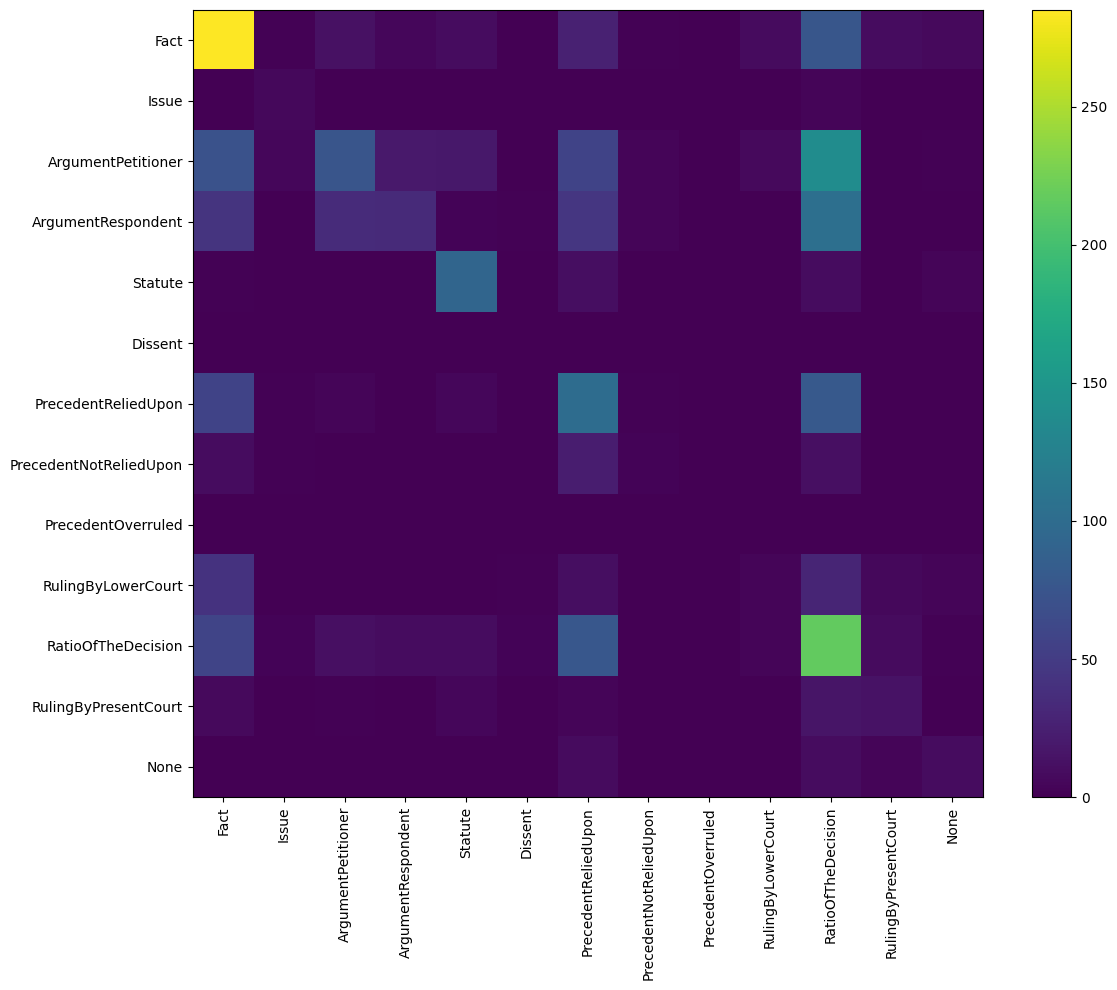

In [13]:
metrics, gold, pred = evaluate(model, dev_loader, len(label_names))
print('Development metrics:', json.dumps(metrics, indent=2))
print(classification_report(gold, pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))
with open(OUTPUT_DIR / 'dev_report.txt', 'w', encoding='utf-8') as f:
    f.write(classification_report(gold, pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))
cm = confusion_matrix(gold, pred, labels=list(range(len(label_names))))
plt.figure(figsize=(12, 10))
plt.imshow(cm, aspect='auto')
plt.xticks(range(len(label_names)), label_names, rotation=90)
plt.yticks(range(len(label_names)), label_names)
plt.colorbar()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'dev_confusion_matrix.png', dpi=150)
plt.show()


In [14]:

from collections import Counter

print("Training label counts:")
print(Counter(r["label"] for r in train_records))

print("\nDevelopment gold label counts:")
print(Counter(r["label"] for r in dev_records))

print("\nDevelopment predicted label counts:")
print(Counter(label_names[i] for i in pred))


Training label counts:
Counter({'RatioOfTheDecision': 4301, 'Fact': 4098, 'PrecedentReliedUpon': 1945, 'ArgumentPetitioner': 1613, 'ArgumentRespondent': 1348, 'Statute': 1099, 'RulingByLowerCourt': 874, 'PrecedentNotReliedUpon': 569, 'RulingByPresentCourt': 307, 'None': 297, 'Dissent': 284, 'Issue': 107, 'PrecedentOverruled': 3})

Development gold label counts:
Counter({'Fact': 444, 'RatioOfTheDecision': 403, 'ArgumentPetitioner': 400, 'ArgumentRespondent': 272, 'PrecedentReliedUpon': 254, 'Statute': 120, 'RulingByLowerCourt': 102, 'PrecedentNotReliedUpon': 50, 'RulingByPresentCourt': 49, 'None': 33, 'Issue': 15})

Development predicted label counts:
Counter({'RatioOfTheDecision': 696, 'Fact': 578, 'PrecedentReliedUpon': 364, 'Statute': 147, 'ArgumentPetitioner': 143, 'ArgumentRespondent': 68, 'RulingByPresentCourt': 44, 'None': 30, 'RulingByLowerCourt': 25, 'Issue': 22, 'PrecedentNotReliedUpon': 15, 'Dissent': 10})


## 6. Generate test prediction JSON

Output maps each document ID to ordered official label strings, one per sentence.

In [15]:
pred_path = save_predictions(model, test_records, label_names, label_to_id, 'model2_lora')
print('Prediction JSON:', pred_path)


Prediction JSON: /kaggle/working/phase3_rr/model2_lora_prediction.json


## Validation notes

- The custom architecture and tokenizer are sourced from the matching Phase-1 notebook and checkpoint loading is strict.
- Attach your own Phase-1 artifacts; they are not bundled.
- LORMA implementation is low-rank multiplicative adaptation; verify the precise course-paper formulation with your instructor before submission.
- Knowledge distillation uses a same-size teacher/student fallback by default. For a genuine compression experiment, use a smaller Phase-1 student checkpoint; do not claim compression unless done.
- Training has not been executed in this file-generation environment; no results are claimed.